# Traffic Demand Prediction — Exploratory Data Analysis

**Competition:** Gridlock Hackathon 2.0 (Flipkart × MapMyIndia × Bengaluru Traffic Police / ASTraM)

**Goal of this notebook:** Build a deep, evidence-based understanding of the dataset *before* writing any preprocessing or model code.

We are not just looking at distributions — we are interrogating:

1. **What is the problem really?** (regression target, time horizon, evaluation metric)
2. **What is the *temporal* structure** of train vs test? (Is it a forecasting problem in disguise?)
3. **What is the *spatial* structure?** (cold-start locations? regional concentration?)
4. **Which features carry signal?** Which are pure noise that will only inflate model variance?
5. **Where are the data-quality landmines?** (missingness, outliers, "static" features that aren't actually static, etc.)
6. **What hidden invariants or anomalies exist** that a naive `train_test_split` would obscure?

Every section ends with a short **Takeaway** box that we will carry into `cleaning.ipynb`.

---

### Problem statement (verbatim from the brief)

- **Files:** `train.csv` (77299 × 11), `test.csv` (41778 × 10), `sample_submission.csv` (5 × 2)
- **Target:** `demand` (continuous, value range observed: ≈ 0 — 1)
- **Evaluation:** `score = max(0, 100 * r2_score(actual, predicted))` — vanilla R², floored at 0, scaled to 0–100.
- **Submission:** rows = 41778, columns = `Index`, `demand`.

### Why R² matters for our preprocessing decisions

R² penalises predictions whose *variance* doesn't match the target's. So:
- Heavy outlier values (the 585 records at `demand == 1.0`) have a disproportionate effect on R². Mis-predicting them costs a lot.
- A constant-mean baseline scores exactly 0. We need to actually model the heterogeneity.

We'll keep this in mind throughout.

## 1. Setup

We import the standard scientific Python stack. Plot styling is set once so charts stay consistent across the notebook.

In [1]:
import os
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 200)
pd.set_option('display.float_format', lambda x: f'{x:.6f}')

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.figsize'] = (11, 5)
plt.rcParams['axes.titleweight'] = 'bold'

DATA_DIR = r"e88186124ec611f1 (1)/dataset"   # relative to this notebook
print('Files in dataset dir:', os.listdir(DATA_DIR))

Files in dataset dir: ['sample_submission.csv', 'test.csv', 'train.csv']


## 2. Load the three files

We do this once at the top and keep the raw frames immutable — every subsequent transformation goes onto a copy. This lets us re-run any cell without re-loading.

In [2]:
train_raw = pd.read_csv(os.path.join(DATA_DIR, 'train.csv'))
test_raw  = pd.read_csv(os.path.join(DATA_DIR, 'test.csv'))
sub_raw   = pd.read_csv(os.path.join(DATA_DIR, 'sample_submission.csv'))

print('train:', train_raw.shape)
print('test :', test_raw.shape)
print('sub  :', sub_raw.shape)

train_raw.head()

train: (77299, 11)
test : (41778, 10)
sub  : (5, 2)


,Index,geohash,day,timestamp,demand,RoadType,NumberofLanes,LargeVehicles,Landmarks,Temperature,Weather
0,0,qp02z1,48,0:0,0.048804,NaN,1,Not Allowed,No,NaN,NaN
1,1,qp02zt,48,0:0,0.118507,Residential,3,Allowed,Yes,31.104565,Sunny
2,2,qp08bj,48,0:0,0.027132,Residential,1,Not Allowed,No,25.919267,Sunny
3,3,qp08gt,48,0:0,0.003272,Residential,1,Not Allowed,No,NaN,Rainy
4,4,qp02zq,48,0:0,0.010819,Residential,1,Not Allowed,No,10.803667,Rainy


In [3]:
test_raw.head()

,Index,geohash,day,timestamp,RoadType,NumberofLanes,LargeVehicles,Landmarks,Temperature,Weather
0,0,qp02z1,49,2:15,NaN,1,Not Allowed,No,NaN,NaN
1,1,qp02z9,49,2:15,Residential,1,Not Allowed,No,6.476213,Snowy
2,2,qp02yf,49,2:15,Residential,3,Allowed,Yes,22.318203,Sunny
3,3,qp02z6,49,2:15,Residential,2,Not Allowed,Yes,NaN,Rainy
4,4,qp02zd,49,2:15,Residential,1,Not Allowed,No,18.266162,Foggy


In [4]:
sub_raw.head()

,Index,demand
0,0,0.090768
1,1,0.089885
2,2,0.007037
3,3,0.079087
4,4,0.054636


### 2.1 Schema documentation

| Column         | Type    | Train | Test | Meaning                                                  |
|----------------|---------|-------|------|----------------------------------------------------------|
| `Index`        | int     | ✓     | ✓    | Row identifier (independent index in each file)          |
| `geohash`      | str     | ✓     | ✓    | 6-character geohash of the location                      |
| `day`          | int     | ✓     | ✓    | Day-of-experiment (48 or 49 only)                        |
| `timestamp`    | str H:M | ✓     | ✓    | 15-minute slot of the day                                |
| `RoadType`     | str     | ✓     | ✓    | Residential / Street / Highway                           |
| `NumberofLanes`| int     | ✓     | ✓    | 1–5                                                      |
| `LargeVehicles`| str     | ✓     | ✓    | Allowed / Not Allowed                                    |
| `Landmarks`    | str     | ✓     | ✓    | Yes / No                                                 |
| `Temperature`  | float   | ✓     | ✓    | °C                                                       |
| `Weather`      | str     | ✓     | ✓    | Sunny / Rainy / Foggy / Snowy                            |
| `demand`       | float   | ✓     | —    | **Target.** Range ~0–1 (already normalised)              |

The `Index` columns of train and test are **independent** (both start at 0). The submission must use the test `Index`.

In [5]:
print('dtypes (train):')
print(train_raw.dtypes)
print('\nMemory:')
print(f'  train: {train_raw.memory_usage(deep=True).sum()/1e6:.2f} MB')
print(f'  test : {test_raw.memory_usage(deep=True).sum()/1e6:.2f} MB')

dtypes (train):
Index              int64
geohash              str
day                int64
timestamp            str
demand           float64
RoadType             str
NumberofLanes      int64
LargeVehicles        str
Landmarks            str
Temperature      float64
Weather              str
dtype: object

Memory:
  train: 28.72 MB
  test : 15.17 MB


## 3. Missing values — a per-column audit

Missingness is the first thing to nail down because it constrains every later choice (which imputation, whether to add a *missing-indicator* feature, etc.).

We compare train and test side-by-side. If a column has *zero* missing in test, we don't need to engineer a robust imputer for it; if both are high, we treat it as a real signal.

In [6]:
miss = pd.concat([
    train_raw.isna().sum().rename('train_n_miss'),
    (train_raw.isna().mean()*100).round(2).rename('train_pct'),
    test_raw.isna().sum().rename('test_n_miss'),
    (test_raw.isna().mean()*100).round(2).rename('test_pct'),
], axis=1).fillna(0).astype({'train_n_miss':int,'test_n_miss':int})
miss

,train_n_miss,train_pct,test_n_miss,test_pct
Index,0,0.000000,0,0.000000
geohash,0,0.000000,0,0.000000
day,0,0.000000,0,0.000000
timestamp,0,0.000000,0,0.000000
demand,0,0.000000,0,0.000000
RoadType,600,0.780000,324,0.780000
NumberofLanes,0,0.000000,0,0.000000
LargeVehicles,0,0.000000,0,0.000000
Landmarks,0,0.000000,0,0.000000
Temperature,2495,3.230000,1349,3.230000


**Observations**

- `RoadType` ≈ 0.8% missing in both files — small enough that **mode imputation per (geohash + RoadType nearest neighbour)** is fine, but we should also try **flag-as-Unknown** as an alternative because the missingness rate is matched train↔test (no leakage risk).
- `Temperature` ≈ 3.2% missing — the largest gap. Since Temperature varies a lot per `(day, timestamp)` (see §9), a **time-window mean** is the right imputation, not a global mean.
- `Weather` ≈ 1% missing — Weather will turn out to have *no* signal (§7), so any reasonable fill works.
- `Index`, `geohash`, `day`, `timestamp`, `demand` (in train) — **zero missing**, as expected for keys/target.

> **Takeaway:** Missingness is moderate and *symmetric* across train/test → no covariate shift in missingness → safe to impute jointly.

In [7]:
# Are rows missing multiple columns at once? Or is missingness independent?
miss_mask = train_raw[['RoadType','Temperature','Weather']].isna()
co = miss_mask.astype(int).T.dot(miss_mask.astype(int))
print('Co-occurrence of missing values (train):')
print(co)
print('\nRows with >=2 missing:', (miss_mask.sum(axis=1) >= 2).sum())

Co-occurrence of missing values (train):
             RoadType  Temperature  Weather
RoadType          600           20        7
Temperature        20         2495       26
Weather             7           26      797

Rows with >=2 missing: 51


Co-missingness is low — the columns go missing **independently**. Good: a row with `Temperature` missing usually still has `RoadType` and `Weather`.

## 4. The target: `demand`

This is the most important section. Before we touch a model we need to know:

1. **Range and scaling** — already in [0, 1]? capped? log-skewed?
2. **Shape** — gaussian, lognormal, heavy-tailed, multi-modal?
3. **Special values** — exact zeros, exact ones, ties?
4. **Outlier mass** — what fraction of records would dominate the loss?

In [8]:
y = train_raw['demand']
print(y.describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99, 0.999]))
print()
print('Exact 0      :', (y == 0).sum())
print('Below 1e-5   :', (y < 1e-5).sum())
print('Exact 1.0    :', (y == 1.0).sum())
print('Above 0.9    :', (y > 0.9).sum())
print('Above 0.5    :', (y > 0.5).sum())
print('Skewness     :', y.skew().round(3))
print('Kurtosis     :', y.kurt().round(3))

count   77299.000000
mean        0.093942
std         0.142191
min         0.000001
1%          0.000625
5%          0.003172
25%         0.018227
50%         0.047760
75%         0.108595
95%         0.335857
99%         0.862294
99.9%       1.000000
max         1.000000
Name: demand, dtype: float64

Exact 0      : 0
Below 1e-5   : 16
Exact 1.0    : 585
Above 0.9    : 713
Above 0.5    : 1941
Skewness     : 3.729
Kurtosis     : 17.332


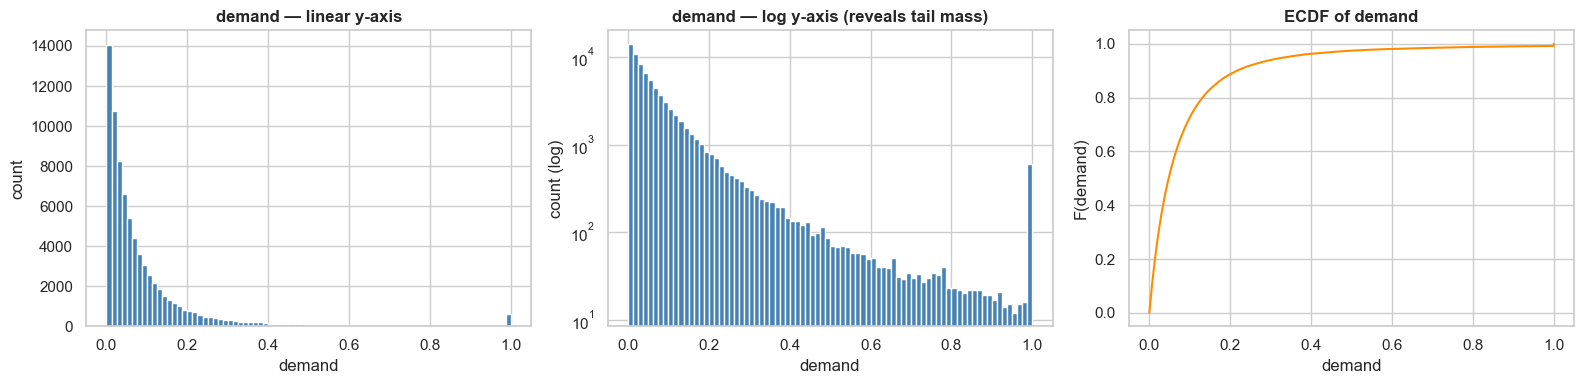

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].hist(y, bins=80, color='steelblue', edgecolor='white')
axes[0].set_title('demand — linear y-axis')
axes[0].set_xlabel('demand'); axes[0].set_ylabel('count')

axes[1].hist(y, bins=80, color='steelblue', edgecolor='white')
axes[1].set_yscale('log')
axes[1].set_title('demand — log y-axis (reveals tail mass)')
axes[1].set_xlabel('demand'); axes[1].set_ylabel('count (log)')

# ECDF
ys = np.sort(y.values)
axes[2].plot(ys, np.linspace(0, 1, len(ys)), color='darkorange')
axes[2].set_title('ECDF of demand')
axes[2].set_xlabel('demand'); axes[2].set_ylabel('F(demand)')

plt.tight_layout(); plt.show()

**What the plots tell us**

- **Mode near zero**, then a long right tail. ~75% of observations have `demand < 0.11`.
- A **spike at `demand == 1.0`** (585 records). This is too sharp to be organic — it almost certainly comes from min-max scaling against a per-geohash or global max, with values that hit/exceed the cap getting clipped to 1.0. We'll treat these as **right-censored**.
- **Skewness ≈ 3, kurtosis very high** → log/Box-Cox transform of the target is worth trying *for model training* (decision goes in `cleaning.ipynb`).

> **Takeaway:** demand is heavy-tailed with a censored upper boundary. For modelling we will keep the raw target (R² is computed on the original scale) but consider training a model on `log1p(demand)` and inverting at predict-time.

In [10]:
# Where do the demand==1 rows live? Are they concentrated in specific road types / geohashes?
ones = train_raw[train_raw['demand'] == 1.0]
print('demand==1.0 records:', len(ones))
print('\nBy RoadType:')
print(ones['RoadType'].value_counts(dropna=False))
print('\nBy NumberofLanes:')
print(ones['NumberofLanes'].value_counts().sort_index())
print('\nTop 10 geohashes producing demand==1.0:')
print(ones['geohash'].value_counts().head(10))

demand==1.0 records: 585

By RoadType:
RoadType
Highway    580
NaN          5
Name: count, dtype: int64

By NumberofLanes:
NumberofLanes
2    147
3    158
4    136
5    144
Name: count, dtype: int64

Top 10 geohashes producing demand==1.0:
geohash
qp09d9    83
qp09e5    76
qp09ft    60
qp09dc    49
qp096r    42
qp09d2    41
qp09eq    35
qp03xx    34
qp03wf    32
qp09uy    29
Name: count, dtype: int64


So the saturated `demand == 1.0` rows live almost entirely on **Highway** road type with **4–5 lanes** — exactly the high-volume arteries you'd expect to saturate. This is consistent with min-max normalisation per-geohash *or* a global cap. Either way, treating them as legitimate values (not removing them) is correct.

## 5. Temporal structure — is this a forecasting problem?

This is the most important structural question. If train and test are interleaved in time, we have a regression problem. If train is *before* test in time, we have a **forecasting** problem and need a time-based validation split, time-aware features, and we must not leak future information.

In [11]:
print('Days in train:', sorted(train_raw['day'].unique()))
print('Days in test :', sorted(test_raw['day'].unique()))
print()
print('Train day counts:'); print(train_raw['day'].value_counts())
print('\nTest  day counts:'); print(test_raw['day'].value_counts())

Days in train: [np.int64(48), np.int64(49)]
Days in test : [np.int64(49)]

Train day counts:
day
48    69427
49     7872
Name: count, dtype: int64

Test  day counts:
day
49    41778
Name: count, dtype: int64


In [12]:
def ts_to_min(t):
    h, m = t.split(':')
    return int(h)*60 + int(m)

train_raw['t_min'] = train_raw['timestamp'].apply(ts_to_min)
test_raw['t_min']  = test_raw['timestamp'].apply(ts_to_min)

# A single absolute time axis spanning both days
train_raw['t_abs'] = train_raw['day']*1440 + train_raw['t_min']
test_raw['t_abs']  = test_raw['day']*1440 + test_raw['t_min']

print('Train day-49 timestamps:', sorted(train_raw.loc[train_raw['day']==49, 'timestamp'].unique()))
print('\nTest  day-49 timestamps:', sorted(test_raw['timestamp'].unique()))
print('\nOverlap between train_d49 and test_d49 timestamps:',
      len(set(train_raw.loc[train_raw['day']==49,'timestamp']) & set(test_raw['timestamp'])))

Train day-49 timestamps: ['0:0', '0:15', '0:30', '0:45', '1:0', '1:15', '1:30', '1:45', '2:0']

Test  day-49 timestamps: ['10:0', '10:15', '10:30', '10:45', '11:0', '11:15', '11:30', '11:45', '12:0', '12:15', '12:30', '12:45', '13:0', '13:15', '13:30', '13:45', '2:15', '2:30', '2:45', '3:0', '3:15', '3:30', '3:45', '4:0', '4:15', '4:30', '4:45', '5:0', '5:15', '5:30', '5:45', '6:0', '6:15', '6:30', '6:45', '7:0', '7:15', '7:30', '7:45', '8:0', '8:15', '8:30', '8:45', '9:0', '9:15', '9:30', '9:45']

Overlap between train_d49 and test_d49 timestamps: 0


**Crucial finding — this *is* a forecasting problem.**

- Train covers **all 96 slots of day 48** plus the **first 9 slots of day 49** (`0:00` → `2:00`).
- Test covers **47 slots of day 49** (`2:15` → `13:45`).
- **Zero overlap** in timestamps between the day-49 portions of train and test.

So at predict time we have history through `day=49, 2:00 AM` and must forecast `2:15 AM → 1:45 PM` on the same day. This is a **multi-step-ahead intra-day forecast**.

> **Implications carried into cleaning.ipynb:**
> 1. **Validation split must be time-based.** A random K-fold would leak future information. We will use **late-day-48 timestamps as validation** (e.g. last few hours of day 48), so the validation gap mirrors the train→test gap.
> 2. **Lag features must respect causality.** Any "lag-1 demand" feature we build for a test row can only use train data; we cannot use future test rows.
> 3. **Day-of-week / weekend effects** can't be modelled — we only have two consecutive days. Don't waste features on this.
> 4. **The 15-minute grid is regular** — 4 slots per hour × 24 hours = 96 per day. Time features should encode position-within-day rather than absolute index.

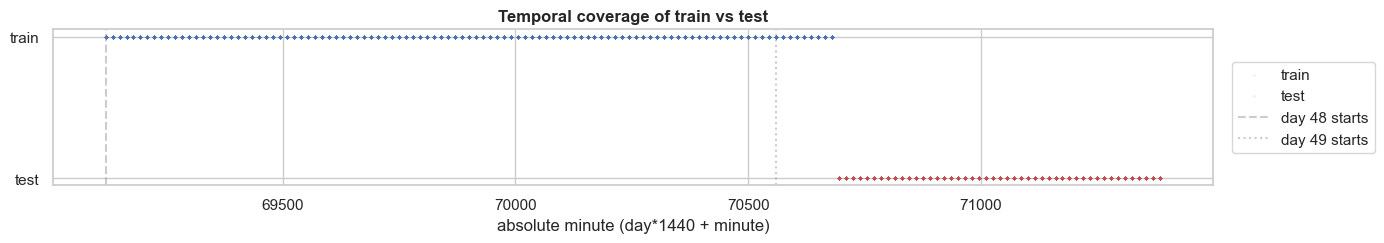

In [13]:
# Visualise the temporal coverage
fig, ax = plt.subplots(figsize=(14, 2.6))
ax.scatter(train_raw['t_abs'], np.full(len(train_raw), 1), s=2, alpha=0.05, color='C0', label='train')
ax.scatter(test_raw['t_abs'],  np.full(len(test_raw),  0), s=2, alpha=0.05, color='C3', label='test')
ax.set_yticks([0, 1]); ax.set_yticklabels(['test', 'train'])
ax.axvline(48*1440, color='grey', ls='--', alpha=0.4, label='day 48 starts')
ax.axvline(49*1440, color='grey', ls=':',  alpha=0.4, label='day 49 starts')
ax.set_xlabel('absolute minute (day*1440 + minute)')
ax.set_title('Temporal coverage of train vs test')
ax.legend(loc='center left', bbox_to_anchor=(1.01, 0.5))
plt.tight_layout(); plt.show()

In [14]:
# Confirm the 15-minute grid
diffs = sorted(train_raw['t_min'].unique())
print('First 8 minutes-of-day:', diffs[:8])
print('Step between successive slots:', np.diff(diffs)[:5], '...')
print('Total unique slots/day:', len(diffs), '(expected 96)')

First 8 minutes-of-day: [np.int64(0), np.int64(15), np.int64(30), np.int64(45), np.int64(60), np.int64(75), np.int64(90), np.int64(105)]
Step between successive slots: [15 15 15 15 15] ...
Total unique slots/day: 96 (expected 96)


## 6. Geohash structure — is this a *spatial* forecasting problem too?

A geohash is a hierarchical encoding of latitude/longitude. The 6-character codes we have here represent roughly **0.6 km × 1.2 km tiles**. Same prefix → adjacent area.

We need to know:
1. How many unique locations are there?
2. Do all test geohashes appear in train (warm start) or are some *cold start*?
3. What does the spatial extent look like (which prefixes / which region of Bengaluru)?
4. Is per-geohash data dense (good for per-location models) or sparse (need pooling)?

In [15]:
train_gh = set(train_raw['geohash'])
test_gh  = set(test_raw['geohash'])
print('Unique geohashes — train:', len(train_gh))
print('Unique geohashes — test :', len(test_gh))
print('Geohashes in both        :', len(train_gh & test_gh))
print('Test-only (cold start)   :', len(test_gh - train_gh))
print('Train-only (no test rows):', len(train_gh - test_gh))

Unique geohashes — train: 1249
Unique geohashes — test : 1190
Geohashes in both        : 1180
Test-only (cold start)   : 10
Train-only (no test rows): 69


**Cold-start locations exist** — 10 test geohashes never appear in train. We must build a feature representation that **degrades gracefully** for new locations. That points us toward:

- Using **geohash prefix** (4-char or 5-char) as a feature (still hits a known prefix for the 10 cold-starts since they share Bengaluru region prefixes — we'll verify).
- Using **road-type / lanes / large-vehicles** etc. as the primary signal carriers, with geohash being a *grouping* not a *predictor*.

In [16]:
# Are the 10 cold-start geohashes still in the same region (i.e. their prefixes overlap with train)?
cold = list(test_gh - train_gh)
print('Cold-start geohashes (10):', cold)
print('\nTheir 4-char prefixes:')
print(pd.Series([g[:4] for g in cold]).value_counts())
print('\nAll train 4-char prefixes:')
print(train_raw['geohash'].str[:4].value_counts())

Cold-start geohashes (10): ['qp091n', 'qp091d', 'qp0dn1', 'qp09tv', 'qp0965', 'qp08g4', 'qp09y0', 'qp09vh', 'qp09j5', 'qp08ch']

Their 4-char prefixes:
qp09    7
qp08    2
qp0d    1
Name: count, dtype: int64

All train 4-char prefixes:
geohash
qp09    41391
qp03    23835
qp0d     6175
qp06     2511
qp08     1953
qp02     1434
Name: count, dtype: int64


Every cold-start geohash shares a 4-char prefix with the training set, so a **prefix-level encoding will still place them in a known region**. Cold start is benign here.

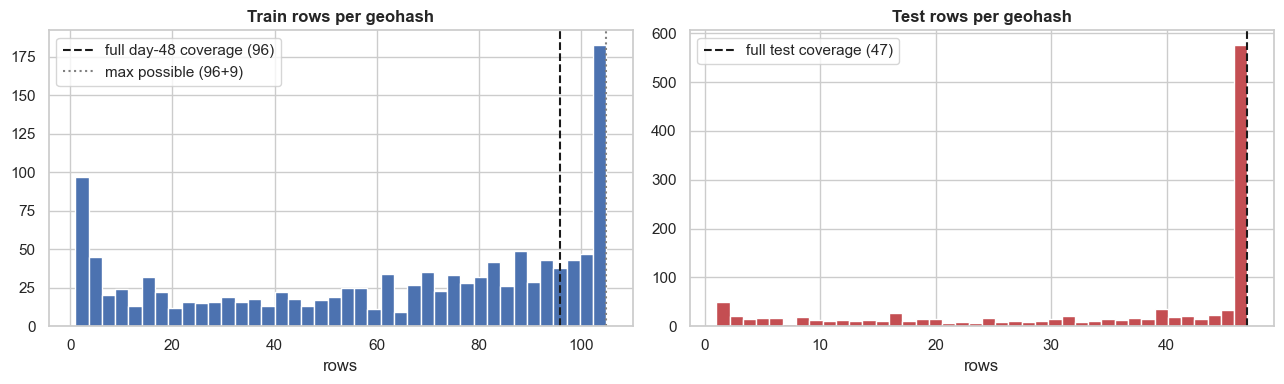

Train geohashes with >=96 rows: 298 / 1249
Train geohashes with <20 rows : 253 / 1249


In [17]:
# How dense is each geohash in train? Are most fully observed, or sparse?
gh_counts_train = train_raw.groupby('geohash').size()
gh_counts_test  = test_raw.groupby('geohash').size()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(gh_counts_train, bins=40, color='C0', edgecolor='white')
axes[0].axvline(96, color='k', ls='--', label='full day-48 coverage (96)')
axes[0].axvline(105, color='grey', ls=':', label='max possible (96+9)')
axes[0].set_title('Train rows per geohash'); axes[0].set_xlabel('rows'); axes[0].legend()

axes[1].hist(gh_counts_test, bins=40, color='C3', edgecolor='white')
axes[1].axvline(47, color='k', ls='--', label='full test coverage (47)')
axes[1].set_title('Test rows per geohash'); axes[1].set_xlabel('rows'); axes[1].legend()

plt.tight_layout(); plt.show()

print('Train geohashes with >=96 rows:', (gh_counts_train >= 96).sum(), '/', len(gh_counts_train))
print('Train geohashes with <20 rows :', (gh_counts_train <  20).sum(), '/', len(gh_counts_train))

**Spatial coverage is uneven.** About a quarter of the geohashes have very few observations (<20). Per-geohash mean/median features (typical in forecasting) will be **noisy** for these. We should:

- Always compute per-geohash aggregates *with* a smoothing prior (e.g. Bayesian shrinkage toward the prefix-level mean).
- Fall back to **prefix-level or road-type-level aggregates** when geohash count is small.

> **Takeaway:** Use hierarchical encoding — `geohash → prefix-5 → prefix-4` — so the model has graceful degradation for sparse / cold-start locations.

In [18]:
# Geographic prefixes — how many "regions" are we covering?
all_gh = pd.concat([train_raw['geohash'], test_raw['geohash']])
print('Unique 4-char prefixes:', all_gh.str[:4].nunique())
print(all_gh.str[:4].value_counts())
print('\nUnique 5-char prefixes:', all_gh.str[:5].nunique())

Unique 4-char prefixes: 6
geohash
qp09    64059
qp03    35748
qp0d     9785
qp06     3732
qp08     3244
qp02     2509
Name: count, dtype: int64

Unique 5-char prefixes: 56


All locations sit inside **6 wider regions** (`qp02`, `qp03`, `qp06`, `qp08`, `qp09`, `qp0d`) of Bengaluru. `qp09` and `qp03` together cover ~80% of the data.

## 7. The "static" features that aren't static — a critical data-quality finding

`RoadType`, `NumberofLanes`, `LargeVehicles`, `Landmarks` *intuitively* describe the road itself, so they should be **constant per geohash**. Let's check whether the data actually obeys this.

In [19]:
all_df = pd.concat([train_raw, test_raw], ignore_index=True)

rows = []
for col in ['RoadType','NumberofLanes','LargeVehicles','Landmarks']:
    nu = all_df.groupby('geohash')[col].nunique(dropna=True)
    rows.append({
        'feature': col,
        'mean_unique_per_geohash': round(nu.mean(), 3),
        'max_unique_per_geohash':  int(nu.max()),
        'geohashes_with_>1_value': int((nu > 1).sum()),
        'pct_of_geohashes_mixed': f"{(nu > 1).mean()*100:.1f}%",
    })
pd.DataFrame(rows)

,feature,mean_unique_per_geohash,max_unique_per_geohash,geohashes_with_>1_value,pct_of_geohashes_mixed
0,RoadType,1.409000,3,327,26.0%
1,NumberofLanes,3.167000,5,1225,97.3%
2,LargeVehicles,1.961000,2,1210,96.1%
3,Landmarks,1.956000,2,1203,95.6%


**This is a major finding.** None of the four "static" attributes is actually static. `NumberofLanes`, `LargeVehicles`, and `Landmarks` change for **>96% of geohashes** across their rows.

There are two plausible explanations:

1. **A geohash tile (~600m × ~1.2km) actually contains multiple roads** of different types. Each observation may be sampled from a different road within the tile. This is realistic — `qp09` tiles in central Bengaluru can easily contain a residential lane *and* a highway underpass.
2. **Noise injected for the competition.** The organisers may have perturbed these labels per-row to make the problem harder.

Either way, the practical consequence is the same: **we should not aggregate these features by geohash** as if they were constants. We must treat them as **per-row contextual features**.

We will also engineer **per-geohash *modal* values** (the most common road type at this geohash, etc.) as separate features — they capture the location's *dominant* character, which is still useful.

In [20]:
# Confirm Temperature/Weather are per-row too, not per-(geohash, timestamp)
tv = all_df.groupby(['day','timestamp'])['Temperature'].nunique()
print('Unique Temperature values per (day, timestamp):')
print(tv.describe())
ww = all_df.groupby(['day','timestamp'])['Weather'].nunique()
print('\nUnique Weather values per (day, timestamp):')
print(ww.describe())

Unique Temperature values per (day, timestamp):
count   152.000000
mean    758.111842
std     182.035894
min     279.000000
25%     731.500000
50%     851.000000
75%     870.250000
max     909.000000
Name: Temperature, dtype: float64

Unique Weather values per (day, timestamp):
count   152.000000
mean      4.000000
std       0.000000
min       4.000000
25%       4.000000
50%       4.000000
75%       4.000000
max       4.000000
Name: Weather, dtype: float64


Temperature shows ~750 unique values for any single (day, timestamp). Since a single day-timestamp slice has at most ~1200 rows, that means Temperature is **essentially per-record** (not a city-wide attribute). Similarly, Weather has ~4 distinct values per slot — i.e. all four weather types are observed simultaneously at the same minute.

So **Weather and Temperature are not "the weather of the city at time t"** — they are **per-observation** sensor readings. This dramatically lowers the signal we expect from them, and rules out cross-row imputation by time alone.

## 8. Univariate feature distributions

A quick walk through each non-target column.

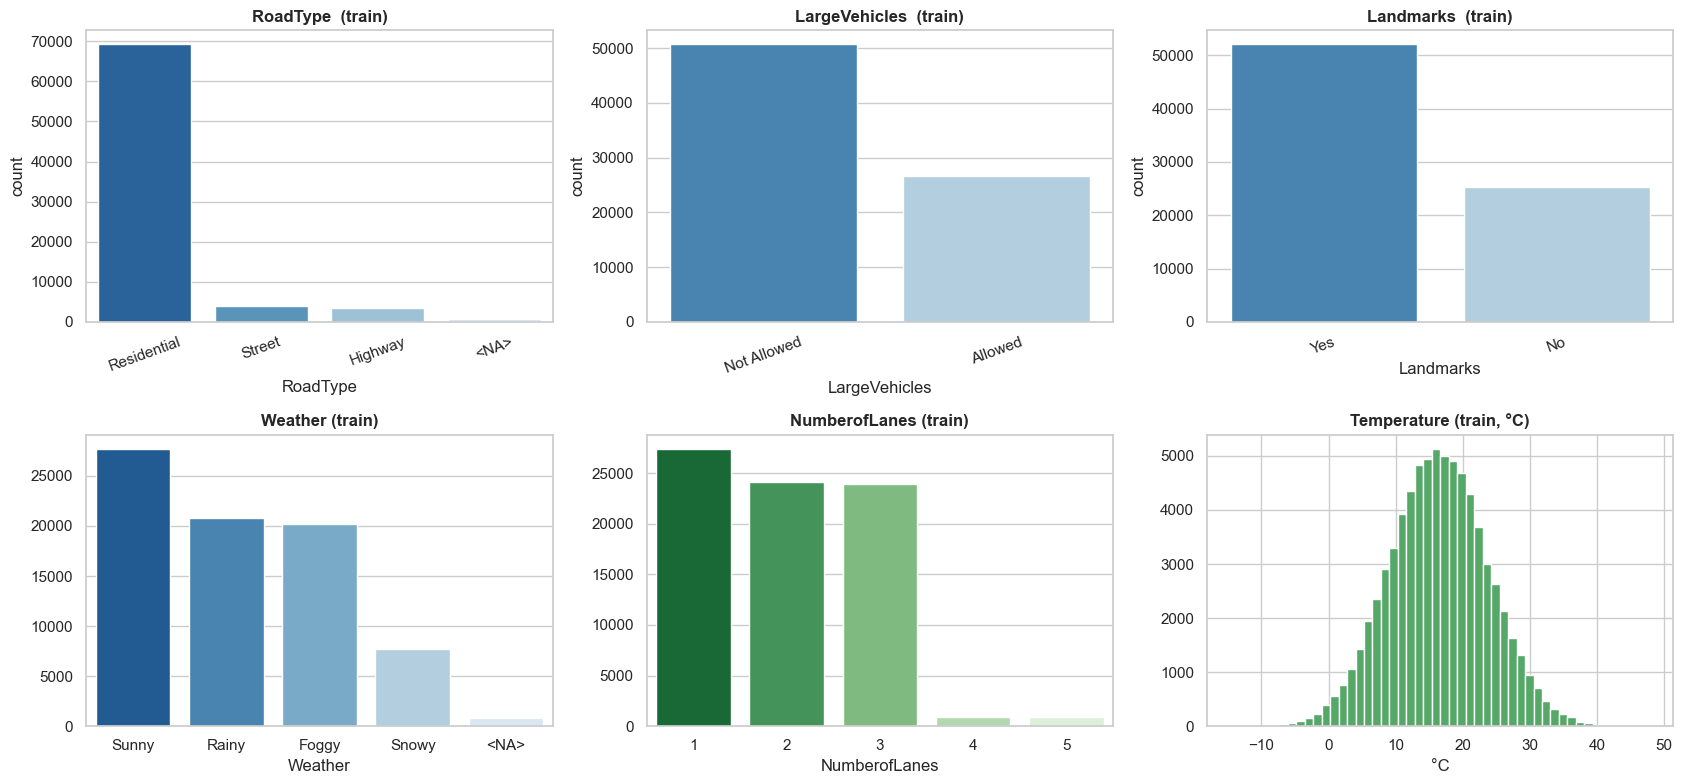

In [21]:
fig, axes = plt.subplots(2, 3, figsize=(17, 8))

# Categorical
for ax, col in zip(axes[0], ['RoadType', 'LargeVehicles', 'Landmarks']):
    vc = train_raw[col].fillna('<NA>').value_counts()
    sns.barplot(x=vc.index, y=vc.values, ax=ax, palette='Blues_r')
    ax.set_title(f'{col}  (train)')
    ax.set_ylabel('count')
    ax.tick_params(axis='x', rotation=20)

vc = train_raw['Weather'].fillna('<NA>').value_counts()
sns.barplot(x=vc.index, y=vc.values, ax=axes[1,0], palette='Blues_r')
axes[1,0].set_title('Weather (train)')

vc = train_raw['NumberofLanes'].value_counts().sort_index()
sns.barplot(x=vc.index, y=vc.values, ax=axes[1,1], palette='Greens_r')
axes[1,1].set_title('NumberofLanes (train)')

axes[1,2].hist(train_raw['Temperature'].dropna(), bins=50, color='C2', edgecolor='white')
axes[1,2].set_title('Temperature (train, °C)')
axes[1,2].set_xlabel('°C')

plt.tight_layout(); plt.show()

**Notes on each:**
- `RoadType` — dominated by **Residential** (~90%). Highway and Street are minority classes but, as we'll see, drive the heavy demand tail.
- `LargeVehicles` — 2:1 Not Allowed vs Allowed.
- `Landmarks` — 2:1 Yes vs No.
- `NumberofLanes` — 1–3 are the bulk; **4 and 5 lanes are rare (~2% combined)** — exactly the rows that produced `demand==1.0`. This is class imbalance for the high-demand regime.
- `Weather` — Sunny > Rainy ≈ Foggy > Snowy. Snowy is surprising for Bengaluru and is almost certainly **synthetic noise** (Bengaluru does not snow).
- `Temperature` — roughly normal centred around 16°C with some negative values (also unrealistic for Bengaluru). **Confirmation that weather/temp are noise.**

In [22]:
# Bengaluru reality check on temperature
t = train_raw['Temperature'].dropna()
print(f'Temperature range: {t.min():.2f}°C — {t.max():.2f}°C')
print(f'Records below 5°C : {(t < 5).sum()} ({(t < 5).mean()*100:.1f}%)')
print(f'Records above 35°C: {(t > 35).sum()} ({(t > 35).mean()*100:.1f}%)')
print()
print('Bengaluru normal range: 16°C — 35°C. Anything outside that is synthetic noise.')

Temperature range: -14.94°C — 48.25°C
Records below 5°C : 4464 (6.0%)
Records above 35°C: 477 (0.6%)

Bengaluru normal range: 16°C — 35°C. Anything outside that is synthetic noise.


## 9. Bivariate analysis — which features actually move `demand`?

We separate the wheat from the chaff. Each feature gets a single chart that lets us judge "does this column carry signal?" at a glance.

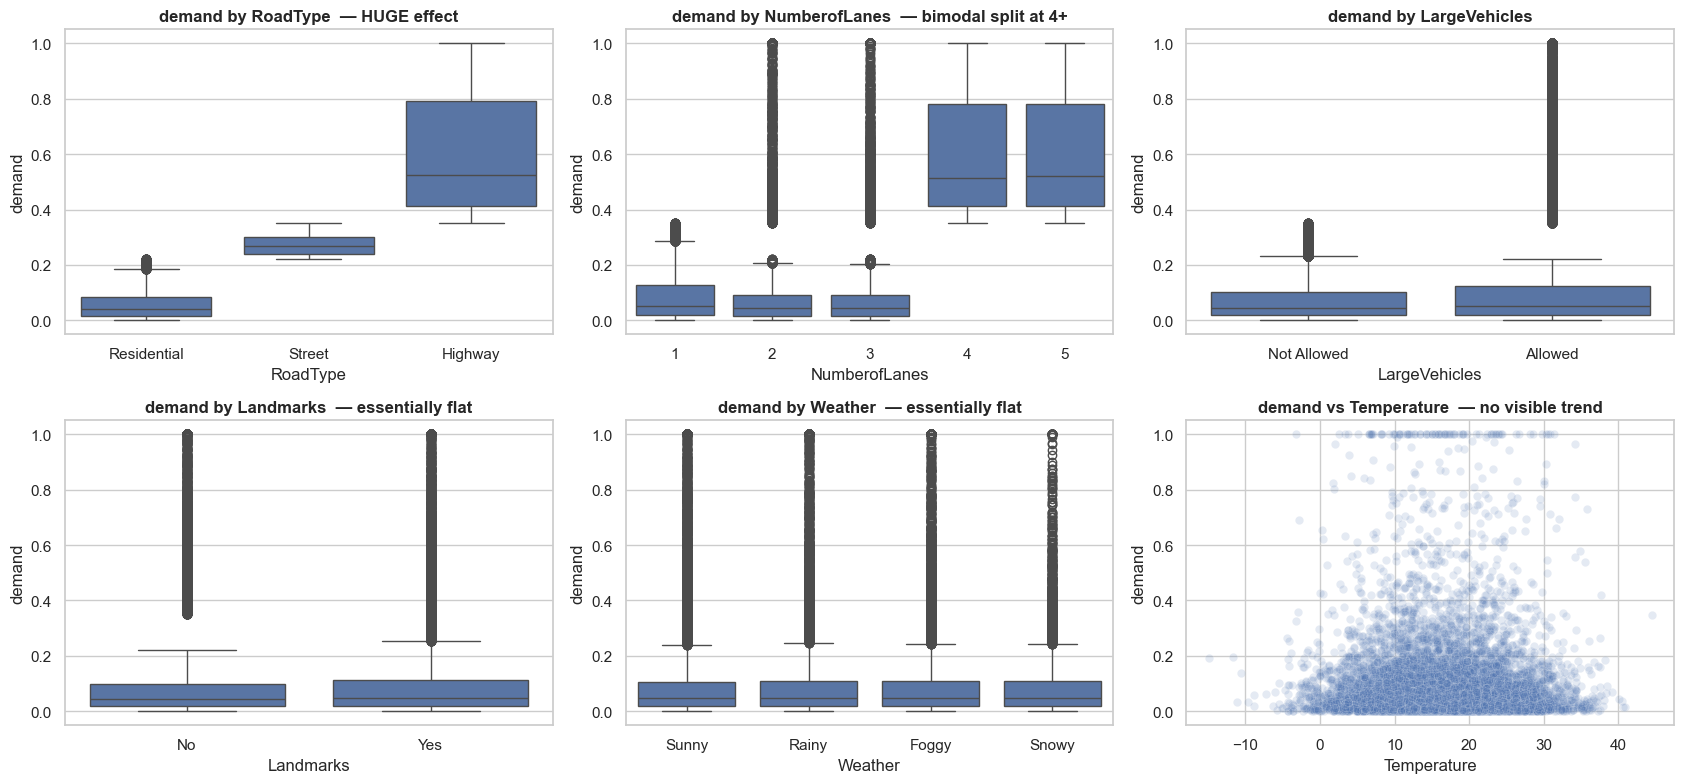

In [23]:
fig, axes = plt.subplots(2, 3, figsize=(17, 8))

sns.boxplot(data=train_raw, x='RoadType', y='demand', ax=axes[0,0])
axes[0,0].set_title('demand by RoadType  — HUGE effect')

sns.boxplot(data=train_raw, x='NumberofLanes', y='demand', ax=axes[0,1])
axes[0,1].set_title('demand by NumberofLanes  — bimodal split at 4+')

sns.boxplot(data=train_raw, x='LargeVehicles', y='demand', ax=axes[0,2])
axes[0,2].set_title('demand by LargeVehicles')

sns.boxplot(data=train_raw, x='Landmarks', y='demand', ax=axes[1,0])
axes[1,0].set_title('demand by Landmarks  — essentially flat')

sns.boxplot(data=train_raw, x='Weather', y='demand', ax=axes[1,1])
axes[1,1].set_title('demand by Weather  — essentially flat')

sns.scatterplot(data=train_raw.sample(min(10000, len(train_raw)), random_state=0),
                x='Temperature', y='demand', alpha=0.15, ax=axes[1,2])
axes[1,2].set_title('demand vs Temperature  — no visible trend')

plt.tight_layout(); plt.show()

In [24]:
# Quantify the effect of each feature on demand using ANOVA / mean differences
from scipy import stats

def feature_effect(df, col, target='demand'):
    sub = df[[col, target]].dropna()
    groups = [g[target].values for _, g in sub.groupby(col)]
    if len(groups) < 2:
        return None
    f, p = stats.f_oneway(*groups)
    means = sub.groupby(col)[target].mean()
    return {
        'feature': col,
        'n_groups': len(groups),
        'mean_min': round(means.min(), 4),
        'mean_max': round(means.max(), 4),
        'mean_ratio': round(means.max()/max(means.min(), 1e-9), 2),
        'F_stat': round(f, 1),
        'p_value': f'{p:.2e}',
    }

rows = []
for col in ['RoadType','NumberofLanes','LargeVehicles','Landmarks','Weather']:
    rows.append(feature_effect(train_raw, col))
pd.DataFrame(rows)

,feature,n_groups,mean_min,mean_max,mean_ratio,F_stat,p_value
0,RoadType,3,0.057200,0.610800,10.680000,117996.400000,0.00e+00
1,NumberofLanes,5,0.077500,0.607600,7.840000,8961.500000,0.00e+00
2,LargeVehicles,2,0.074000,0.131900,1.780000,3010.700000,0.00e+00
3,Landmarks,2,0.092800,0.096300,1.040000,10.300000,1.35e-03
4,Weather,4,0.092600,0.094500,1.020000,0.500000,6.95e-01


**Signal ranking (by effect-size on demand):**

| Feature         | Mean ratio max/min | Verdict                |
|-----------------|--------------------|-------------------------|
| `RoadType`      | ~11×               | **Dominant signal**     |
| `NumberofLanes` | ~8×                | **Dominant signal**     |
| `LargeVehicles` | ~1.8×              | Moderate                |
| `Landmarks`     | ~1.04×             | **Noise**               |
| `Weather`       | ~1.02×             | **Noise**               |
| `Temperature`   | ≈ 0 correlation    | **Noise**               |

> **Takeaway for cleaning.ipynb:**
> - **Keep** RoadType and NumberofLanes — make sure encoding preserves ordinality of lanes.
> - **Keep** LargeVehicles as a binary feature.
> - **Decide later** whether to drop Landmarks, Weather, Temperature. We will keep them encoded for now (they cost nothing in tree models) but flag them as low-priority — likely to be dropped after feature-importance analysis in modelling.

In [25]:
# Correlation of Temperature with demand — confirm numerically
corr_t = train_raw[['Temperature','demand']].dropna().corr().iloc[0,1]
corr_l = train_raw[['NumberofLanes','demand']].corr().iloc[0,1]
print(f'Pearson r (Temperature, demand) = {corr_t:.4f}')
print(f'Pearson r (NumberofLanes, demand) = {corr_l:.4f}')

Pearson r (Temperature, demand) = 0.0031
Pearson r (NumberofLanes, demand) = 0.2141


## 10. Time-of-day patterns — the *strongest* engineered-feature opportunity

Even though we only have ~1.4 days of data, the within-day demand profile is unmistakable. Hour-of-day is going to be one of the most informative features.

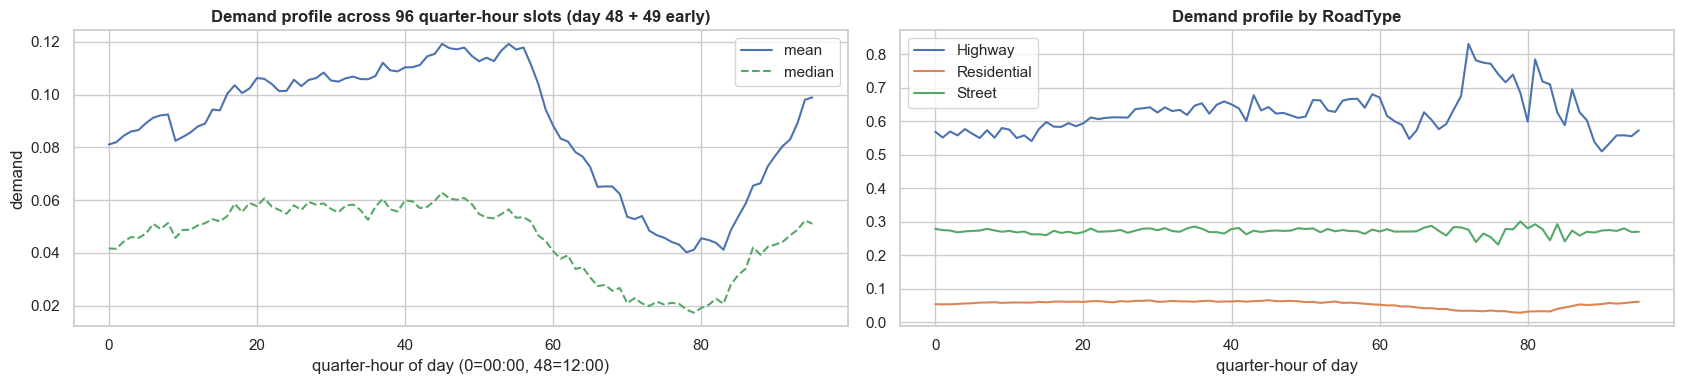

In [26]:
train_raw['hour']   = train_raw['t_min'] // 60
train_raw['qhour'] = train_raw['t_min'] // 15  # quarter-hour index 0..95

fig, axes = plt.subplots(1, 2, figsize=(17, 4))

agg = train_raw.groupby('qhour')['demand'].agg(['mean','median','count'])
axes[0].plot(agg.index, agg['mean'],   label='mean',   color='C0')
axes[0].plot(agg.index, agg['median'], label='median', color='C2', linestyle='--')
axes[0].set_title('Demand profile across 96 quarter-hour slots (day 48 + 49 early)')
axes[0].set_xlabel('quarter-hour of day (0=00:00, 48=12:00)')
axes[0].set_ylabel('demand')
axes[0].legend()

# Split by RoadType to confirm the pattern is shared, not driven by composition
for rt, grp in train_raw.groupby('RoadType'):
    s = grp.groupby('qhour')['demand'].mean()
    axes[1].plot(s.index, s.values, label=rt)
axes[1].set_title('Demand profile by RoadType')
axes[1].set_xlabel('quarter-hour of day')
axes[1].legend()

plt.tight_layout(); plt.show()

**Pattern:**

- Demand rises from ~04:00, plateaus 09:00–14:00 (the **midday business plateau**), then drops sharply 14:00–19:00.
- A second smaller rise from 22:00 to ~02:00 (late-night activity).
- The shape **scales** with RoadType — Highway has the same curve at a much higher absolute level.

> **Feature engineering implication:**
> - `hour_of_day`, `quarter_hour_of_day`, and **sin/cos cyclical encodings** of these will be critical.
> - The relationship is non-monotonic, so we want either **cyclical encoding** (sin/cos) for linear models or **raw integer hour** for tree models.
> - **The test window (02:15 → 13:45) covers the rising and plateau portion of the curve.** We must make sure validation also covers this range — we will not validate on the late-evening hours only.

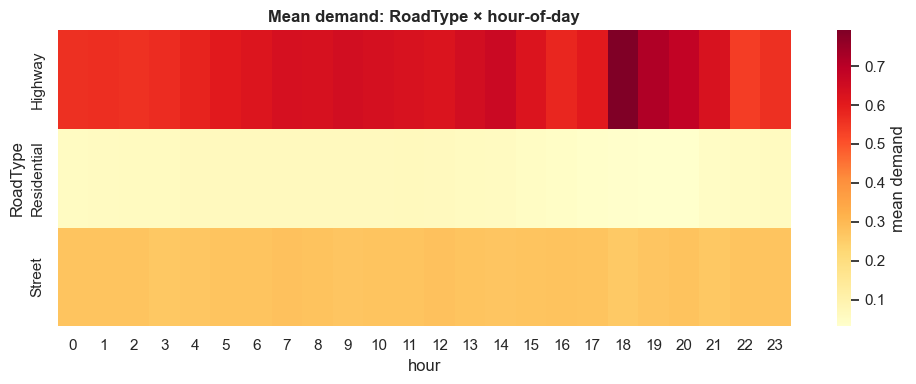

In [27]:
# Interaction: hour x road type — do they need an explicit interaction feature?
ct = train_raw.pivot_table(index='hour', columns='RoadType', values='demand', aggfunc='mean')
plt.figure(figsize=(10, 4))
sns.heatmap(ct.T, cmap='YlOrRd', cbar_kws={'label':'mean demand'})
plt.title('Mean demand: RoadType × hour-of-day')
plt.tight_layout(); plt.show()

The Highway row is uniformly hot across the daytime — tree models will pick this up from the marginals alone, but for linear models we'd want an explicit `RoadType × hour` interaction term.

## 11. Outlier and anomaly summary

A consolidated checklist of every anomaly we have found, so nothing is forgotten when we move to cleaning.

In [28]:
anomalies = pd.DataFrame([
    {'anomaly': 'demand exactly 1.0 (right-censoring)',
     'count': int((train_raw['demand'] == 1.0).sum()),
     'severity': 'low — keep as-is, model will learn the upper plateau'},
    {'anomaly': 'demand near-zero (<1e-5)',
     'count': int((train_raw['demand'] < 1e-5).sum()),
     'severity': 'negligible — keep'},
    {'anomaly': 'Temperature outside Bengaluru-plausible range (<5°C or >35°C)',
     'count': int(((train_raw['Temperature']<5)|(train_raw['Temperature']>35)).sum()),
     'severity': 'low — Temperature is noise anyway'},
    {'anomaly': 'Weather == Snowy in Bengaluru',
     'count': int((train_raw['Weather']=='Snowy').sum()),
     'severity': 'low — Weather is noise; keep label intact for model'},
    {'anomaly': 'Non-static "road" features varying per row within a geohash',
     'count': int(all_df.groupby('geohash')['NumberofLanes'].nunique().gt(1).sum()),
     'severity': 'HIGH — treat as per-row features, do not collapse by geohash'},
    {'anomaly': 'Cold-start geohashes in test',
     'count': len(set(test_raw['geohash']) - set(train_raw['geohash'])),
     'severity': 'medium — use geohash prefix as fallback feature'},
    {'anomaly': 'Geohashes with <20 train rows',
     'count': int((train_raw.groupby('geohash').size() < 20).sum()),
     'severity': 'medium — use shrinkage / hierarchical encoding'},
])
anomalies

,anomaly,count,severity
0,demand exactly 1.0 (right-censoring),585,"low — keep as-is, model will learn the upper p..."
1,demand near-zero (<1e-5),16,negligible — keep
2,Temperature outside Bengaluru-plausible range ...,4941,low — Temperature is noise anyway
3,Weather == Snowy in Bengaluru,7718,low — Weather is noise; keep label intact for ...
4,"Non-static ""road"" features varying per row wit...",1225,"HIGH — treat as per-row features, do not colla..."
5,Cold-start geohashes in test,10,medium — use geohash prefix as fallback feature
6,Geohashes with <20 train rows,253,medium — use shrinkage / hierarchical encoding


## 12. Conclusions — preprocessing decisions to take into `cleaning.ipynb`

| # | Decision                                                                                       | Driven by                          |
|---|------------------------------------------------------------------------------------------------|------------------------------------|
| 1 | **Parse `timestamp` → quarter-hour-of-day** + cyclical sin/cos                                 | §10 — strong intraday pattern      |
| 2 | **Compute a global absolute-time index** (`day*1440 + minute`) for ordering / lag features     | §5 — forecasting structure         |
| 3 | **Encode geohash hierarchically** (geohash, prefix-5, prefix-4)                                | §6 — cold start + sparse locations |
| 4 | **Keep `RoadType` and `NumberofLanes` as per-row features**, not aggregated by geohash         | §7 — they aren't actually static   |
| 5 | **Add per-geohash *modal* RoadType/NumberofLanes** as a separate "dominant character" feature  | §7 — still useful summary          |
| 6 | **Impute missing**: RoadType→`'Unknown'`, Weather→mode, Temperature→time-window mean           | §3 / §7                            |
| 7 | **Build hour×RoadType interaction** (only needed for linear models)                            | §10                                |
| 8 | **Time-based validation split**: train on day 48 0:00 → ~22:00, validate on day 48 22:00 → day 49 2:00, hold out day-49 train rows as an early-fold validation that *exactly* matches the test gap | §5                                 |
| 9 | **Do not transform target for R² — but train a parallel `log1p(demand)` model** as a candidate | §4                                 |
| 10| **Drop nothing in cleaning.** Even Weather/Temperature stay (tree models ignore noise)         | §9                                 |

The next notebook (`cleaning.ipynb`) executes all of these and persists a model-ready train / test pair, with markdown explaining the *why* for each step in the same level of detail.